In [ ]:
import pandas as pd
df= pd.read_csv("insurance.csv")




In [ ]:
df.head(5)

,age,sex,bmi,children,smoker,region,charges
0,19.0,female,27.900,0.0,yes,southwest,16884.92400
1,18.0,male,33.770,1.0,no,southeast,1725.55230
2,28.0,male,33.000,3.0,no,southeast,4449.46200
3,33.0,male,22.705,0.0,no,northwest,21984.47061
4,32.0,male,28.880,0.0,no,northwest,3866.85520


In [ ]:
df.tail(5)

,age,sex,bmi,children,smoker,region,charges
1333,50.0,male,30.97,3.0,no,northwest,10600.5483
1334,18.0,female,31.92,0.0,no,northeast,2205.9808
1335,18.0,female,36.85,0.0,no,southeast,1629.8335
1336,21.0,female,25.80,0.0,no,southwest,2007.9450
1337,61.0,female,29.07,0.0,yes,northwest,29141.3603


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1335 non-null   float64
 1   sex       1336 non-null   object 
 2   bmi       1335 non-null   float64
 3   children  1336 non-null   float64
 4   smoker    1336 non-null   object 
 5   region    1336 non-null   object 
 6   charges   1337 non-null   float64
dtypes: float64(4), object(3)
memory usage: 73.3+ KB


In [ ]:
df.describe()

,age,bmi,children,charges
count,1335.000000,1335.000000,1336.000000,1337.000000
mean,39.238951,30.657903,1.096557,13271.853650
std,14.047648,6.101257,1.205650,12114.429349
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.255000,0.000000,4738.268200
50%,39.000000,30.400000,1.000000,9377.904700
75%,51.000000,34.637500,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


In [ ]:
df.isnull().sum()

,0
age,3
sex,2
bmi,3
children,2
smoker,2
region,2
charges,1


In [ ]:
print("Rows:",df.shape)

NameError: name 'df' is not defined

In [ ]:
print("Rows:",df.shape[0])
print("Columns:",df.shape[1])

Rows: 1338
Columns: 7


In [ ]:
print(df.columns.tolist())

['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


In [ ]:
df.dtypes

,0
age,float64
sex,object
bmi,float64
children,float64
smoker,object
region,object
charges,float64


In [ ]:
df

,age,sex,bmi,children,smoker,region,charges
0,19.0,female,27.900,0.0,yes,southwest,16884.92400
1,18.0,male,33.770,1.0,no,southeast,1725.55230
2,28.0,male,33.000,3.0,no,southeast,4449.46200
3,33.0,male,22.705,0.0,no,northwest,21984.47061
4,32.0,male,28.880,0.0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50.0,male,30.970,3.0,no,northwest,10600.54830
1334,18.0,female,31.920,0.0,no,northeast,2205.98080
1335,18.0,female,36.850,0.0,no,southeast,1629.83350
1336,21.0,female,25.800,0.0,no,southwest,2007.94500


In [ ]:
input_columns = ['age', 'sex', 'bmi', 'children', 'smoker', 'region']
target_column = 'charges'
print("Input variables:", input_columns)
print("Target variable:", target_column)

Input variables: ['age', 'sex', 'bmi', 'children', 'smoker', 'region']
Target variable: charges


In [ ]:
df.duplicated().sum()

np.int64(1)

In [ ]:
df = df.drop_duplicates()

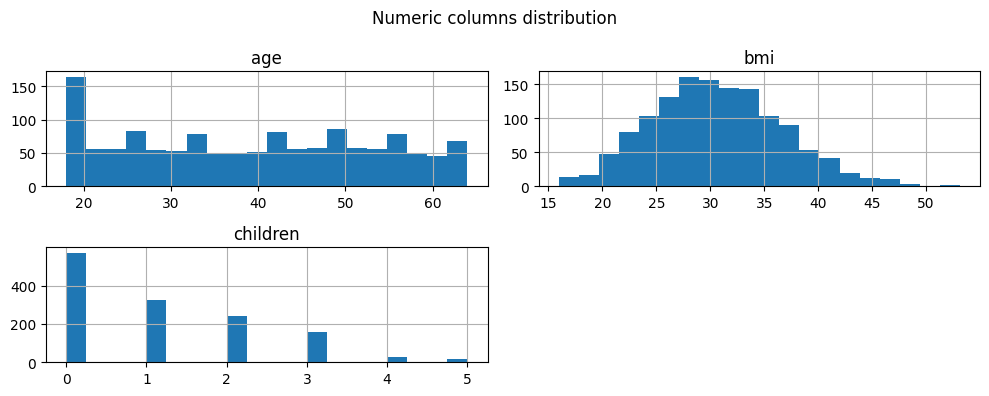

In [ ]:
import matplotlib.pyplot as plt
numeric_columns = ["age","bmi","children"]
df[numeric_columns].hist(bins= 20,figsize=(10,4))
plt.suptitle("Numeric columns distribution")
plt.tight_layout()
plt.show()

In [ ]:
for column in numeric_columns:
  skew_value = df[column].skew()
  if -0.5<= skew_value <=0.5:
    print(column, "-> Use mean")
  else:
    print(column,"-> Use median")

age -> Use mean
bmi -> Use mean
children -> Use median


In [ ]:
df["age"] = df["age"].fillna(df["age"].mean())
df["bmi"] = df["bmi"].fillna(df["bmi"].mean())
df["children"] = df["children"].fillna(df["children"].median())

/tmp/ipykernel_368/2719152656.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["age"] = df["age"].fillna(df["age"].mean())
/tmp/ipykernel_368/2719152656.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["bmi"] = df["bmi"].fillna(df["bmi"].mean())
/tmp/ipykernel_368/2719152656.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/panda

In [ ]:
df.isnull().sum()

,0
age,0
sex,2
bmi,0
children,0
smoker,2
region,2
charges,1


In [ ]:
df["sex"] = df["sex"].fillna(df["sex"].mode()[0])
df["smoker"] = df["smoker"].fillna(df["smoker"].mode()[0])
df["region"] = df["region"].fillna(df["region"].mode()[0])

/tmp/ipykernel_368/3395687920.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["sex"] = df["sex"].fillna(df["sex"].mode()[0])
/tmp/ipykernel_368/3395687920.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["smoker"] = df["smoker"].fillna(df["smoker"].mode()[0])
/tmp/ipykernel_368/3395687920.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.p

In [ ]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,1


In [ ]:
df = df.dropna(subset = ["charges"])

In [ ]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [ ]:
df.shape

(1336, 7)

In [ ]:
df_encoded= pd.get_dummies(df,columns=["sex","smoker","region"],dtype=int)
df_encoded.head()

,age,bmi,children,charges,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,19.0,27.900,0.0,16884.92400,1,0,0,1,0,0,0,1
1,18.0,33.770,1.0,1725.55230,0,1,1,0,0,0,1,0
2,28.0,33.000,3.0,4449.46200,0,1,1,0,0,0,1,0
3,33.0,22.705,0.0,21984.47061,0,1,1,0,0,1,0,0
4,32.0,28.880,0.0,3866.85520,0,1,1,0,0,1,0,0


In [ ]:
X_df= df_encoded.drop("charges",axis=1)
y_df= df_encoded["charges"]
print("Input shape:",X_df.shape)
print("Output shape:",y_df.shape)

Input shape: (1336, 11)
Output shape: (1336,)


In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test= train_test_split(X_df,y_df,train_size = 0.8,test_size=0.2,random_state=42)
print("Training rows;",X_train.shape[0])
print("Testing rows;",X_test.shape[0])

Training rows; 1068
Testing rows; 268


In [ ]:
from sklearn.preprocessing import StandardScaler
df_scaler= StandardScaler()
scale_columns= ["age","bmi","children"]
x_train= X_train.copy()
x_test= X_test.copy()
X_train[scale_columns]= df_scaler.fit_transform(X_train[scale_columns])
X_test[scale_columns]= df_scaler.transform(X_test[scale_columns])

In [ ]:
X_train

,age,bmi,children,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
1114,-1.162538,-1.016075,-0.924494,0,1,1,0,1,0,0,0
968,-1.306018,-0.811850,0.754689,0,1,1,0,1,0,0,0
600,-1.521239,1.406511,-0.924494,1,0,1,0,0,0,1,0
171,0.702707,-0.058616,-0.924494,0,1,1,0,0,0,0,1
276,-1.449499,-1.660168,0.754689,0,1,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...
1097,-1.234278,0.515198,-0.924494,0,1,1,0,0,0,1,0
1132,1.276629,1.591719,-0.924494,0,1,1,0,1,0,0,0
1296,-1.521239,-0.749011,-0.924494,0,1,1,0,1,0,0,0
862,1.133148,0.476337,0.754689,1,0,1,0,0,1,0,0


In [ ]:
from sklearn.linear_model import Lasso
linear_model = Lasso()

In [ ]:
linear_model.fit(X_train,y_train)
print("Linear Regression Model trained successfully")



Linear Regression Model trained successfully


In [ ]:
pred = linear_model.predict(X_test)

In [ ]:
df_result = pd.DataFrame({"Actual":y_test,"Predicted":pred})
df_result.head(3)

,Actual,Predicted
900,8688.85885,8390.390594
1064,5708.86700,5432.522006
1256,11436.73815,14577.110871


In [ ]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
mse = mean_squared_error(y_test,pred)
mae = mean_absolute_error(y_test,pred)
remse = mse**0.5
r2 = r2_score(y_test,pred)
print("Mean Squared Error:",mse)
print("Root Mean Squared Error:",remse)
print("Mean Absolute Error:",mae)
print("R2 Score:",r2)

Mean Squared Error: 40197430.57729199
Root Mean Squared Error: 6340.144365650674
Mean Absolute Error: 4331.51595760895
R2 Score: 0.7346722218332257


In [ ]:
new_customer = pd.DataFrame({
    "age":[35],"sex":["male"],"bmi":[27.5],"children":[2],"smoker":["no"],"region":["southwest"]
})
new_customer

,age,sex,bmi,children,smoker,region
0,35,male,27.5,2,no,southwest


In [ ]:
new_customer_encoded = pd.get_dummies(
    new_customer,
    columns=["sex","smoker","region"],
    dtype=int

)

new_customer_encoded=new_customer_encoded.reindex(columns=X_df.columns,fill_value=0)
new_customer_encoded

,age,bmi,children,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,35,27.5,2,0,1,1,0,0,0,0,1


In [ ]:
new_customer_encoded[scale_columns] = df_scaler.transform(new_customer_encoded[scale_columns])
new_customer_encoded

,age,bmi,children,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,-0.301656,-0.521636,0.754689,0,1,1,0,0,0,0,1


In [ ]:
unknown_customer_prediction=(linear_model.predict(new_customer_encoded))[0]
print("Unknown customer charges:",unknown_customer_prediction)

Unknown customer charges: 6540.189913784172


In [ ]:
import joblib
joblib.dump(linear_model,'model.pkl')
print("model Dumped!")

model Dumped!
